# Loan Decision Prediction — Approved / Declined

Train a Logistic Regression **classification** model on `MUC02_Credit_PreScreening_Dataset.csv`, evaluate it, save the complete preprocessing pipeline, and try predictions for new applications.

**Important:** The target is the bank's historical `decision`, not actual repayment/default. This is a learning/deployment prototype, not a production lending decision system. Human oversight, fairness/compliance review, and independent validation are required before any real-world use.

## 1. Libraries and dataset

In [1]:
# If needed: %pip install pandas numpy matplotlib seaborn scikit-learn joblib

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
DATA_PATH = Path("MUC02_Credit_PreScreening_Dataset.csv")
RANDOM_STATE = 42

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Place the CSV beside this notebook: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.isna().sum().sort_values(ascending=False).rename("missing_values").to_frame())
display(df["decision"].value_counts(dropna=False).to_frame("count"))

Shape: (12000, 19)


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


,missing_values
credit_score,1039
monthly_income,441
application_id,0
age,0
application_date,0
gender,0
city,0
employment_type,0
city_tier,0
years_in_current_job,0


,count
decision,
Approved,6353
Declined,5647


## 2. Clean data and engineer features

In [2]:
df = df.copy()
df = df[df["decision"].isin(["Approved", "Declined"])].copy()

# Create new-to-credit flag before imputing credit scores.
df["is_ntc"] = df["credit_score"].isna().astype(int)

# Correct likely annual income entered as monthly income, as indicated in the use-case reference.
high_income = df["monthly_income"] > 600_000
print("Income values above ₹6,00,000 corrected:", int(high_income.sum()))
df.loc[high_income, "monthly_income"] = df.loc[high_income, "monthly_income"] / 12

# Fill missing income using employment-type median, then overall median.
by_employment_median = df.groupby("employment_type")["monthly_income"].transform("median")
df["monthly_income"] = df["monthly_income"].fillna(by_employment_median)
df["monthly_income"] = df["monthly_income"].fillna(df["monthly_income"].median())

income = df["monthly_income"].replace(0, np.nan)
df["foir"] = (df["existing_emi"] + df["proposed_emi"]) / income
df["loan_to_income"] = df["loan_amount"] / (income * 12)

numeric_features = [
    "credit_score", "is_ntc", "foir", "loan_to_income",
    "delinquencies_24m", "num_active_loans", "years_in_current_job",
    "age", "tenure_months", "city_tier"
]
categorical_features = ["employment_type", "loan_purpose"]
feature_columns = numeric_features + categorical_features

missing = [c for c in feature_columns + ["decision"] if c not in df.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

X = df[feature_columns].copy()
y = df["decision"].astype(str)

print("Rows retained:", len(df))
print("Approval/decline distribution (%):")
display((y.value_counts(normalize=True) * 100).rename("percent").to_frame())

Income values above ₹6,00,000 corrected: 12
Rows retained: 12000
Approval/decline distribution (%):


,percent
decision,
Approved,52.941667
Declined,47.058333


## 3. Visualize the target

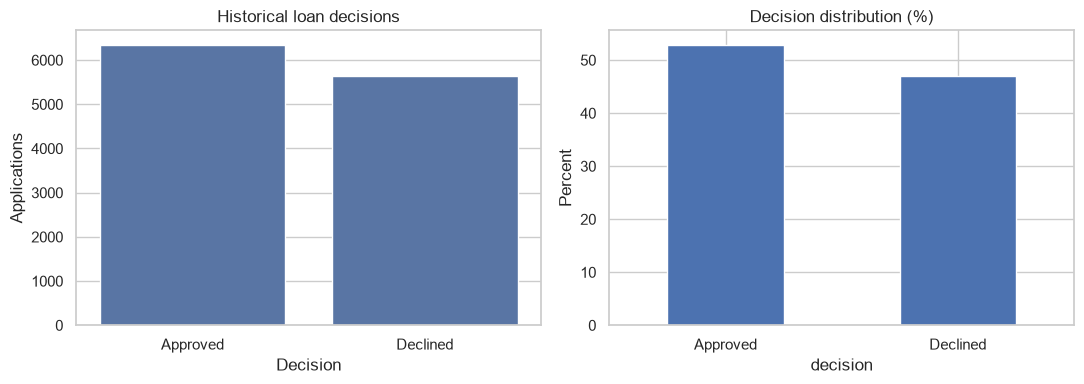

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="decision", order=["Approved", "Declined"], ax=axes[0])
axes[0].set_title("Historical loan decisions")
axes[0].set_xlabel("Decision")
axes[0].set_ylabel("Applications")

(y.value_counts(normalize=True).reindex(["Approved", "Declined"]) * 100).plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Decision distribution (%)")
axes[1].set_ylabel("Percent")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 4. Train/test split and preprocessing

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)
print("Training complete.")
print("Classes:", model.named_steps["classifier"].classes_.tolist())

Training complete.
Classes: ['Approved', 'Declined']


## 5. Evaluate the Approved / Declined classifier

Accuracy:         0.791
Macro precision:  0.791
Macro recall:     0.789
Macro F1-score:   0.789

Classification report:
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.81      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



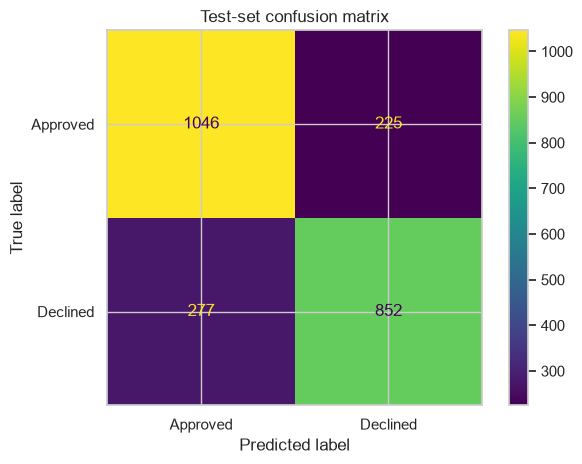

ROC-AUC for Declined class: 0.867


In [5]:
y_pred = model.predict(X_test)
classes = list(model.named_steps["classifier"].classes_)

print(f"Accuracy:         {accuracy_score(y_test, y_pred):.3f}")
print(f"Macro precision:  {precision_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(f"Macro recall:     {recall_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(f"Macro F1-score:   {f1_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=classes)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes).plot(values_format="d")
plt.title("Test-set confusion matrix")
plt.tight_layout()
plt.show()

if "Declined" in classes and len(set(y_test)) == 2:
    prob_declined = model.predict_proba(X_test)[:, classes.index("Declined")]
    y_declined_binary = (y_test == "Declined").astype(int)
    print(f"ROC-AUC for Declined class: {roc_auc_score(y_declined_binary, prob_declined):.3f}")

In [ ]:
## 6. Save the complete trained pipeline

In [6]:
MODEL_PATH = Path("loan_approve_decline_pipeline.joblib")
joblib.dump(model, MODEL_PATH)
print("Saved:", MODEL_PATH.resolve())
print("The artifact includes preprocessing and Logistic Regression.")

Saved: C:\Users\thula\Downloads\Calibo_Homeworks\Use_Case_2\loan_approve_decline_pipeline.joblib
The artifact includes preprocessing and Logistic Regression.


## 7. Prepare and predict a new application

Provide the raw fields below. The function calculates `foir`, `loan_to_income`, and `is_ntc` using the same definitions as training. Missing numeric/categorical fields can be imputed by the pipeline, but all listed raw fields should normally be supplied.

In [7]:
def prepare_application(application: dict) -> pd.DataFrame:
    required = [
        "age", "employment_type", "years_in_current_job", "monthly_income",
        "existing_emi", "credit_score", "credit_history_months",
        "num_active_loans", "delinquencies_24m", "loan_purpose",
        "loan_amount", "tenure_months", "proposed_emi", "city_tier"
    ]
    missing = [k for k in required if k not in application]
    if missing:
        raise ValueError(f"Missing application fields: {missing}")

    a = dict(application)
    if pd.notna(a["monthly_income"]) and a["monthly_income"] > 600_000:
        a["monthly_income"] = a["monthly_income"] / 12

    income = a["monthly_income"]
    if pd.isna(income) or income == 0:
        foir, loan_to_income = np.nan, np.nan
    else:
        foir = (a["existing_emi"] + a["proposed_emi"]) / income
        loan_to_income = a["loan_amount"] / (income * 12)

    is_ntc = int(pd.isna(a["credit_score"]) or a["credit_history_months"] == 0)
    return pd.DataFrame([{
        "credit_score": a["credit_score"],
        "is_ntc": is_ntc,
        "foir": foir,
        "loan_to_income": loan_to_income,
        "delinquencies_24m": a["delinquencies_24m"],
        "num_active_loans": a["num_active_loans"],
        "years_in_current_job": a["years_in_current_job"],
        "age": a["age"],
        "tenure_months": a["tenure_months"],
        "city_tier": a["city_tier"],
        "employment_type": a["employment_type"],
        "loan_purpose": a["loan_purpose"]
    }], columns=feature_columns)


def predict_loan_decision(application: dict) -> dict:
    features = prepare_application(application)
    label = str(model.predict(features)[0])
    probabilities = model.predict_proba(features)[0]
    probs = {
        str(cls): round(float(p), 4)
        for cls, p in zip(model.named_steps["classifier"].classes_, probabilities)
    }
    return {
        "predicted_decision": label,
        "class_probabilities": probs,
        "note": "Prediction of historical decisions only; human review is required."
    }

example_application = {
    "age": 30,
    "employment_type": "Salaried",
    "years_in_current_job": 4,
    "monthly_income": 65000,
    "existing_emi": 8000,
    "credit_score": 735,
    "credit_history_months": 48,
    "num_active_loans": 1,
    "delinquencies_24m": 0,
    "loan_purpose": "Medical",
    "loan_amount": 300000,
    "tenure_months": 36,
    "proposed_emi": 10250,
    "city_tier": 1
}
print(json.dumps(predict_loan_decision(example_application), indent=2))

{
  "predicted_decision": "Approved",
  "class_probabilities": {
    "Approved": 0.8341,
    "Declined": 0.1659
  },
  "note": "Prediction of historical decisions only; human review is required."
}


## 8. Load the saved model in a future API

In a separate Python service, load the artifact with `joblib.load("loan_approve_decline_pipeline.joblib")`. Keep the feature engineering logic in `prepare_application()` available in that service and validate incoming input types/ranges.

### Before deployment
- Validate on newer, out-of-time data.
- Evaluate error rates separately by relevant applicant groups.
- Remember the model predicts past analyst decisions, not repayment/default.
- Add monitoring, secure logging, model versioning, and human review.
- Obtain appropriate credit-policy, fairness, and compliance approval before any real-world use.